# ¿Conviene cortar más de lo necesario?

### Hackathon WQCC · pista Explorer

**Participante:** `Alberto Galarza`
**Fecha:** 12 de noviembre de 2026

---

## La pregunta

Cuando un circuito no cabe en el chip, hay que cortarlo. Eso ya se sabe.

Lo que me pregunté es otra cosa: **si el circuito cabe, ¿siempre conviene no cortar?** ¿Y si cabe
justo, conviene cortarlo igual y usar fragmentos todavía más pequeños?

La regla que trae el paquete responde que no. Su política es: *usar ejecución directa si cabe, y si
no cabe, elegir el corte con menor sobrecosto de muestreo*. O sea, cortar lo mínimo indispensable.

Mi resultado es que **esa regla pierde en 3 de las 4 familias de circuitos**, y que se puede hacer
mejor con información que el planificador ya tiene antes de ejecutar nada.

## Lo que encontré, en corto

1. Cortar **cambia sesgo por varianza**. Fragmentos más chicos pasan por menos compuertas ruidosas
   (menos sesgo) pero reciben menos mediciones cada uno (más varianza).
2. La varianza **se puede predecir gratis**: el error estándar que ya reporta el planificador acierta
   la dispersión real medida con 20 réplicas.
3. El sesgo se puede **aproximar** con la profundidad de dos qubits del fragmento.
4. Juntando las dos, armé una regla que elige el ancho sin mirar nunca la respuesta correcta.
   La **ajusté en una familia y la probé en las otras tres**. Acierta el ancho exacto en 1 de 3,
   pero **baja el error un 9 % respecto a la regla del paquete**, porque donde se equivoca casi no
   cuesta.
5. Esa diferencia entre "acertar el ancho" y "bajar el error" resultó ser el hallazgo más útil:
   el óptimo es plano, así que el argmin es mala vara de medir.
6. Donde falla de verdad (familia modular) sé explicar por qué, y lo dejo reportado.

## Mapa del cuaderno

| Sección | Qué hay |
|---|---|
| 1 | Entorno y verificación |
| 2 | El caso y cómo se corta |
| 3 | Una ejecución completa: reconstrucción, registro de mediciones, incertidumbre |
| 4 | El experimento: 4 familias × 4 anchos × 20 réplicas |
| 5 | Descomposición sesgo / varianza |
| 6 | ¿El error estándar reportado predice la dispersión real? |
| 7 | **La regla predictiva** y su prueba fuera de muestra |
| 8 | Marcador: regla del paquete vs mi regla vs el óptimo |
| 9 | Dónde falla y por qué |
| 10 | Control: una familia donde cortar no ayuda |
| 11 | El equilibrio ancho–profundidad–mediciones |
| 12 | Limitaciones |
| 13 | Declaración de uso de IA |

> **Tiempo de ejecución:** el cuaderno completo tarda unos **5 minutos**. La sección 4 es la pesada
> (320 ejecuciones del simulador). Las secciones 1 a 3 corren en segundos.

---
# 1. Entorno

In [1]:
import sys, pathlib

RUTA_PAQUETE = None   # Si el cuaderno no está junto a python/, pon aquí esa ruta.

def localizar_paquete():
    if RUTA_PAQUETE:
        return pathlib.Path(RUTA_PAQUETE)
    aqui = pathlib.Path.cwd()
    for base in [aqui, *aqui.parents][:4]:
        cand = base / "python"
        if (cand / "wqcc_planner" / "__init__.py").exists():
            return cand
    raise FileNotFoundError("No encuentro python/wqcc_planner. Descomprime "
                            "WQCC-Planner-Materials.zip y pon este cuaderno dentro.")

ruta = localizar_paquete(); sys.path.insert(0, str(ruta))
print("Paquete:", ruta)

Paquete: /Users/albertogalarza/Desktop/Hackathon-WQCC/python


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_addon_cutting
from wqcc_planner import make_instance, plan, execute, ideal_reference

print("python              ", sys.version.split()[0])
print("qiskit              ", qiskit.__version__)
print("qiskit-aer          ", qiskit_aer.__version__)
print("qiskit-addon-cutting", qiskit_addon_cutting.__version__)

Matplotlib is building the font cache; this may take a moment.


python               3.14.4
qiskit               2.5.2
qiskit-aer           0.17.2
qiskit-addon-cutting 0.10.0


### Nota sobre la versión de Python

La guía recomienda Python 3.12. Yo lo corrí en **3.14** porque el instalador de 3.12 me falló en mi
Mac y verifiqué antes que las siete dependencias del `requirements.txt` tienen wheels precompilados
para 3.14 en Apple Silicon. `check_environment.py` da `"status": "pass"`. Si lo corres en 3.12
debería dar lo mismo; las semillas están fijas, así que los números son reproducibles.

---
# 2. El caso y dónde corta la librería

Empiezo con un caso concreto para que se vea el mecanismo, y después lo generalizo.

**Familia QAOA/MaxCut, 6 qubits, semilla 7, ruido `mild`, 12 000 mediciones.**

El observable es el promedio de correlaciones ZZ sobre las aristas del grafo. Con esta semilla el
generador produce un **grafo de camino** 0–1–2–3–4–5: cinco aristas, cada una con coeficiente 0.2.

Elijo esa familia porque las aristas del grafo **son** los puntos de corte candidatos (cada arista
es una compuerta `RZZ`), así que puedo razonar sobre lo que hace el buscador automático en vez de
tratarlo como caja negra.

In [3]:
N_QUBITS, SEMILLA, RUIDO, PRESUPUESTO = 6, 7, "mild", 12_000

caso = make_instance(family="qaoa", n_qubits=N_QUBITS, seed=SEMILLA,
                     max_width=3, shots=PRESUPUESTO, noise=RUIDO)

print("Instancia:", caso.instance_id)
print("Qubits:", caso.circuit.num_qubits, "| ancho máximo del chip:", caso.max_width)
print("¿Cabe entero?", "SÍ" if caso.circuit.num_qubits <= caso.max_width else "NO → hay que cortar")
print()
print(caso.circuit.draw(output="text", fold=100))

Instancia: qaoa-n6-l1-s7-mild-line-w3
Qubits: 6 | ancho máximo del chip: 3
¿Cabe entero? NO → hay que cortar

     ┌───┐                ┌────────────┐                                                           
q_0: ┤ H ├─■──────────────┤ Rx(1.0972) ├───────────────────────────────────────────────────────────
     ├───┤ │ZZ(-0.58757)  └────────────┘ ┌────────────┐                                            
q_1: ┤ H ├─■──────────────■──────────────┤ Rx(1.0972) ├────────────────────────────────────────────
     ├───┤                │ZZ(-0.58757)  └────────────┘ ┌────────────┐                             
q_2: ┤ H ├────────────────■──────────────■──────────────┤ Rx(1.0972) ├─────────────────────────────
     ├───┤                               │ZZ(-0.58757)  └────────────┘ ┌────────────┐              
q_3: ┤ H ├───────────────────────────────■──────────────■──────────────┤ Rx(1.0972) ├──────────────
     ├───┤                                              │ZZ(-0.58757)  └────────────┘┌────

In [4]:
print("Observable:")
for p, c in caso.observable.to_list():
    print(f"   {p}   {c.real:+.3f}")
print("\nMetadatos:")
for k, v in caso.metadata.items():
    print(f"   {k}: {v}")

IDEAL = ideal_reference(caso)
print(f"\nValor ideal (sin ruido, sin cortes): {IDEAL:+.6f}")

Observable:
   IIIIZZ   +0.200
   IIIZZI   +0.200
   IIZZII   +0.200
   IZZIII   +0.200
   ZZIIII   +0.200

Metadatos:
   layers: 1
   generator_version: 1
   edges: [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]
   gammas: [0.5875668266232669]
   betas: [0.5486069004847878]
   target: mean edge ZZ; MaxCut fraction = (1 - expectation) / 2

Valor ideal (sin ruido, sin cortes): -0.389617


`ideal_reference` es un diagnóstico de organizador: simula el circuito completo sin ruido por vector
de estado. **El planificador nunca lo ve** y no entra en ninguna decisión ni en ninguna estimación
reportada. Solo lo uso para medir cuánto me equivoco. En la sección 7 esto importa mucho: la regla
que propongo tampoco lo usa.

In [5]:
plan_cortado = plan(caso, "auto_cut", "coefficient")
s = plan_cortado.summary()

print(f"Decisión: {plan_cortado.decision}  |  estrategia: {s['selected_strategy']}")
print(f"Subexperimentos:                {s['experiments']}")
print(f"Ancho máx. de subexperimento:   {s['maximum_experiment_width']}")
print(f"Profundidad máx. de 2 qubits:   {s['maximum_two_qubit_depth']}")
print(f"Sobrecosto de muestreo (gamma): {s['maximum_qpd_overhead']:.3f}")
print("\nParticiones:")
for etiqueta, qubits in s["partition_map"].items():
    print(f"   fragmento {etiqueta}: qubits {qubits}")
print("\nCompuertas cortadas:")
for c in s["cut_locations"]:
    print(f"   {c['gate'].upper()}({', '.join(f'{p:.4f}' for p in c['parameters'])}) en qubits {c['qubits']}")

Decisión: cut  |  estrategia: auto_cut
Subexperimentos:                60
Ancho máx. de subexperimento:   3
Profundidad máx. de 2 qubits:   4
Sobrecosto de muestreo (gamma): 4.447

Particiones:
   fragmento 0: qubits [0, 1, 2]
   fragmento 1: qubits [3, 4, 5]

Compuertas cortadas:
   RZZ(-0.5876) en qubits [2, 3]


Un solo corte, en la `RZZ` entre los qubits 2 y 3 — justo el medio de la cadena. Parte el circuito
en dos mitades de 3 qubits.

Ese único corte genera **60 subexperimentos**. No son 2: la reconstrucción de una `RZZ` cortada usa
una descomposición cuasi-probabilística con coeficientes **con signo**, que son 6 subexperimentos
por corte, multiplicados por los 5 términos de Pauli del observable y las combinaciones de
fragmentos. El `gamma` de 4.45 es el precio: así de inflada queda la varianza respecto a no cortar,
a igualdad de mediciones.

---
# 3. Una ejecución completa

Todo corre en Aer con el modelo de ruido sintético. `execute` gasta exactamente las mediciones
asignadas, lleva el registro y verifica de forma independiente que su reconstrucción coincide con la
de Qiskit.

In [6]:
res = execute(caso, plan_cortado, seed=2026)

print(f"Reconstruido:  {res['estimate']:+.6f}")
print(f"Ideal:         {IDEAL:+.6f}")
print(f"Error:         {abs(res['estimate']-IDEAL):.6f}")
print()
print(f"Error estándar de muestreo: ±{res['sampling_standard_error_approx']:.6f}")
lo, hi = res["sampling_interval"]
print(f"Intervalo 95 %: [{lo:+.4f}, {hi:+.4f}]")
print(f"Mediciones gastadas: {res['physical_shots']} / {res['shot_budget']}")
print(f"Reconstrucción cruzada con Qiskit: {res['qiskit_reconstruction_agrees']}")

Reconstruido:  -0.391223
Ideal:         -0.389617
Error:         0.001606

Error estándar de muestreo: ±0.021127
Intervalo 95 %: [-0.8897, +0.1001]
Mediciones gastadas: 12000 / 12000
Reconstrucción cruzada con Qiskit: True


In [7]:
ledger = pd.DataFrame(res["experiments"])
cols = [c for c in ["index","shots","width","term","qpd_term","partition","mean","mean_variance"] if c in ledger.columns]
print(f"Subexperimentos: {len(ledger)} | mediciones por subexperimento: "
      f"min={ledger['shots'].min()}, máx={ledger['shots'].max()}, mediana={int(ledger['shots'].median())}")
display(ledger[cols].head(8))

Subexperimentos: 60 | mediciones por subexperimento: min=50, máx=518, mediana=158


,shots,width,term,qpd_term,partition,mean,mean_variance
0,518,3,0,0,0,-0.378378,0.001657
1,158,3,0,1,0,0.088608,0.006319
2,158,3,0,2,0,-0.012658,0.006368
3,158,3,0,3,0,-0.367089,0.005511
4,158,3,0,4,0,-0.455696,0.005047
5,50,3,0,5,0,-0.280000,0.018808
6,518,3,0,0,1,1.000000,0.000000
7,158,3,0,1,1,1.000000,0.000000


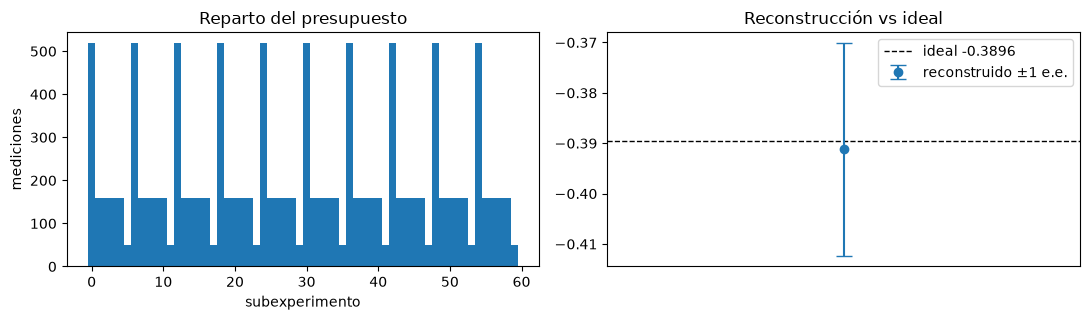

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].bar(range(len(ledger)), ledger["shots"].values, width=1.0)
ax[0].set_xlabel("subexperimento"); ax[0].set_ylabel("mediciones"); ax[0].set_title("Reparto del presupuesto")
ax[1].axhline(IDEAL, color="k", ls="--", lw=1, label=f"ideal {IDEAL:+.4f}")
ax[1].errorbar([0], [res["estimate"]], yerr=res["sampling_standard_error_approx"],
               fmt="o", capsize=6, label="reconstruido ±1 e.e.")
ax[1].set_xlim(-.6,.6); ax[1].set_xticks([]); ax[1].set_title("Reconstrucción vs ideal"); ax[1].legend()
plt.tight_layout(); plt.show()

**Sobre el intervalo.** Sale enorme — cubre casi todo el rango posible para una cantidad acotada en
[−1, +1]. Es un intervalo de unión-Hoeffding propagado por productos de 60 subexperimentos, y es
válido pero inútilmente conservador. El **error estándar** (±0.021) describe mucho mejor la
precisión real; la sección 6 lo comprueba contra la dispersión medida.

Y un punto que importa para todo lo que sigue: **ni el intervalo ni el error estándar acotan la
distancia al ideal.** Ambos describen la cantidad ruidosa reconstruida. El sesgo del hardware queda
fuera por construcción. Esa es exactamente la grieta que explota la sección 7.

---
# 4. El experimento

Una sola ejecución no dice nada: es una muestra de una cantidad ruidosa. Y una sola familia no dice
si algo generaliza. Así que:

- **4 familias**: QAOA/MaxCut, dinámica de espines, energía variacional, circuitos modulares
- **4 anchos máximos**: 2, 3, 4 y 6 (con 6 el circuito cabe entero, no se corta)
- **20 semillas de simulación** por configuración
- Todo lo demás fijo: 6 qubits, semilla de circuito 7, ruido `mild`, 12 000 mediciones

De cada configuración saco dos cantidades que **se miden distinto**:

| | Definición | Qué captura |
|---|---|---|
| **Sesgo** | media de las 20 estimaciones − ideal | el ruido del hardware; no baja con más mediciones |
| **Dispersión** | desviación estándar entre las 20 | el error de muestreo; sí baja con más mediciones |

El **RMSE** los combina. Separarlos es lo que hace que el experimento diga algo en vez de solo dar
un número.

In [9]:
SEMILLAS = [2026,7,101,555,9090,31337,42,1234,8008,606,
            77,314,2718,1618,999,123,456,789,2020,4040]
FAMILIAS = ["qaoa","spin","variational","modular"]
ANCHOS   = [2,3,4,6]

def medir(familia, ancho, estrategia="auto_cut", presupuesto=PRESUPUESTO, semillas=SEMILLAS):
    inst = make_instance(family=familia, n_qubits=N_QUBITS, seed=SEMILLA,
                         max_width=ancho, shots=presupuesto, noise=RUIDO)
    ideal = ideal_reference(inst)                 # solo para medir el error, nunca para decidir
    p = plan(inst, estrategia, "coefficient"); s = p.summary()
    est, se = [], []
    for sd in semillas:
        r = execute(inst, p, seed=sd)
        est.append(r["estimate"]); se.append(r["sampling_standard_error_approx"])
    e = np.array(est)
    return dict(familia=familia, ancho=ancho, ideal=ideal,
                subexp=s["experiments"], prof_2q=s["maximum_two_qubit_depth"],
                gamma=s["maximum_qpd_overhead"], cortes=len(s["cut_locations"]),
                media=e.mean(), sesgo=e.mean()-ideal, ee_sesgo=e.std(ddof=1)/np.sqrt(len(e)),
                dispersion=e.std(ddof=1), rmse=np.sqrt(((e-ideal)**2).mean()),
                ee_reportado=float(np.mean(se)))
print("Listo. La siguiente celda tarda ~4 minutos.")

Listo. La siguiente celda tarda ~4 minutos.


In [10]:
filas = []
for fam in FAMILIAS:
    for w in ANCHOS:
        f = medir(fam, w); filas.append(f)
        print(f"{fam:12s} ancho={w}  subexp={f['subexp']:4d}  prof2q={f['prof_2q']:2d}  "
              f"sesgo={f['sesgo']:+.4f}±{f['ee_sesgo']:.4f}  disp={f['dispersion']:.4f}  "
              f"RMSE={f['rmse']:.4f}", flush=True)

D = pd.DataFrame(filas)

qaoa         ancho=2  subexp= 540  prof2q= 2  sesgo=+0.0070±0.0085  disp=0.0381  RMSE=0.0378
qaoa         ancho=3  subexp=  60  prof2q= 4  sesgo=+0.0232±0.0046  disp=0.0205  RMSE=0.0306
qaoa         ancho=4  subexp=  60  prof2q= 6  sesgo=+0.0382±0.0038  disp=0.0168  RMSE=0.0415
qaoa         ancho=6  subexp=   5  prof2q=10  sesgo=+0.0347±0.0018  disp=0.0079  RMSE=0.0355
spin         ancho=2  subexp= 648  prof2q= 2  sesgo=-0.0288±0.0102  disp=0.0455  RMSE=0.0529
spin         ancho=3  subexp=  72  prof2q= 4  sesgo=-0.0249±0.0054  disp=0.0241  RMSE=0.0342
spin         ancho=4  subexp=  72  prof2q= 6  sesgo=-0.0257±0.0051  disp=0.0228  RMSE=0.0340
spin         ancho=6  subexp=   6  prof2q=10  sesgo=-0.0423±0.0013  disp=0.0057  RMSE=0.0427
variational  ancho=2  subexp=1188  prof2q= 1  sesgo=-0.0362±0.0156  disp=0.0699  RMSE=0.0771
variational  ancho=3  subexp= 132  prof2q= 2  sesgo=-0.0192±0.0065  disp=0.0292  RMSE=0.0343
variational  ancho=4  subexp= 132  prof2q= 3  sesgo=-0.0205±0.0069  di

---
# 5. Descomposición sesgo / varianza

In [11]:
display(D[["familia","ancho","subexp","prof_2q","gamma","sesgo","ee_sesgo","dispersion","rmse"]].round(4))

,familia,ancho,subexp,prof_2q,gamma,sesgo,ee_sesgo,dispersion,rmse
0,qaoa,2,540,2,19.7715,0.0070,0.0085,0.0381,0.0378
1,qaoa,3,60,4,4.4465,0.0232,0.0046,0.0205,0.0306
2,qaoa,4,60,6,4.4465,0.0382,0.0038,0.0168,0.0415
3,qaoa,6,5,10,1.0000,0.0347,0.0018,0.0079,0.0355
4,spin,2,648,2,23.0229,-0.0288,0.0102,0.0455,0.0529
5,spin,3,72,4,4.7982,-0.0249,0.0054,0.0241,0.0342
6,spin,4,72,6,4.7982,-0.0257,0.0051,0.0228,0.0340
7,spin,6,6,10,1.0000,-0.0423,0.0013,0.0057,0.0427
8,variational,2,1188,1,81.0000,-0.0362,0.0156,0.0699,0.0771
9,variational,3,132,2,9.0000,-0.0192,0.0065,0.0292,0.0343


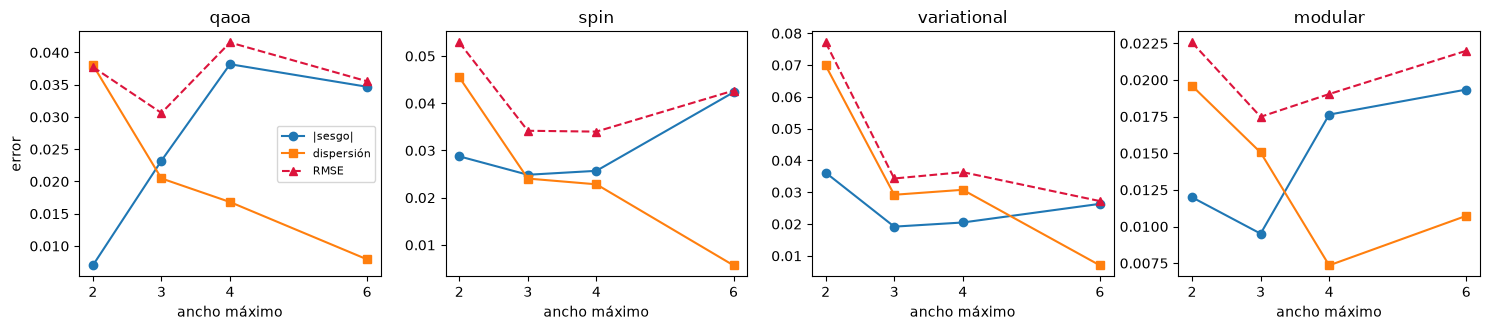

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharex=True)
for ax, fam in zip(axes, FAMILIAS):
    d = D[D.familia==fam].sort_values("ancho")
    ax.plot(d.ancho, d.sesgo.abs(), "o-", label="|sesgo|")
    ax.plot(d.ancho, d.dispersion, "s-", label="dispersión")
    ax.plot(d.ancho, d.rmse, "^--", color="crimson", label="RMSE")
    ax.set_title(fam); ax.set_xlabel("ancho máximo"); ax.invert_xaxis()
    ax.set_xticks(ANCHOS)
axes[0].set_ylabel("error"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Lo que se ve

El patrón se repite en las cuatro familias, aunque con intensidades distintas:

- **Hacia la izquierda** (cortar más, ancho menor): la **dispersión sube** mucho. Es el efecto
  esperado — más subexperimentos, mismo presupuesto, menos mediciones cada uno.
- **Hacia la derecha** (cortar menos): el **sesgo sube**. Los fragmentos son más profundos y
  acumulan más ruido. La profundidad de dos qubits pasa de 2 a 10 en QAOA.

Las dos curvas se cruzan. **El RMSE tiene su mínimo donde se cruzan**, y ese punto no está en el
mismo ancho para todas las familias. Esa es toda la historia del trabajo.

---
# 6. ¿Se puede predecir la mitad fácil?

Antes de construir nada, compruebo algo: el planificador **ya reporta** un error estándar de
muestreo, calculado sin conocer la respuesta. Si ese número acierta la dispersión que mido con 20
réplicas, entonces tengo la mitad del modelo gratis.

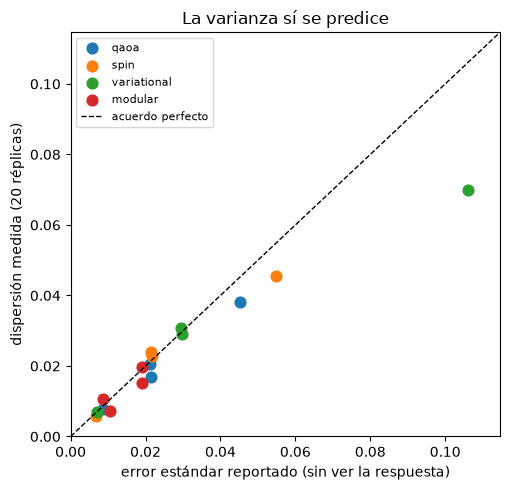

correlación: 0.9746
razón medido/reportado: mediana 0.945, rango [0.658, 1.235]


In [13]:
fig, ax = plt.subplots(figsize=(5.2,5))
for fam in FAMILIAS:
    d = D[D.familia==fam]
    ax.scatter(d.ee_reportado, d.dispersion, label=fam, s=60)
lims = [0, max(D.ee_reportado.max(), D.dispersion.max())*1.08]
ax.plot(lims, lims, "k--", lw=1, label="acuerdo perfecto")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("error estándar reportado (sin ver la respuesta)")
ax.set_ylabel("dispersión medida (20 réplicas)")
ax.set_title("La varianza sí se predice"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

r = np.corrcoef(D.ee_reportado, D.dispersion)[0,1]
razon = (D.dispersion/D.ee_reportado)
print(f"correlación: {r:.4f}")
print(f"razón medido/reportado: mediana {razon.median():.3f}, rango [{razon.min():.3f}, {razon.max():.3f}]")

Los puntos caen prácticamente sobre la diagonal. El error estándar reportado **sí predice** la
dispersión real, con una ligera tendencia a sobreestimarla en los anchos más agresivos (donde hay
cientos de subexperimentos con pocas mediciones cada uno y la aproximación de la varianza del
producto se vuelve floja).

**Conclusión: la mitad de varianza del problema está resuelta sin costo.** Lo que falta es el sesgo.

---
# 7. La regla predictiva

### La idea

Si el error total es
$$\text{RMSE}^2 \approx \text{sesgo}^2 + \text{varianza}$$
y ya tengo la varianza gratis, me falta estimar el sesgo **sin mirar la respuesta**.

Mi hipótesis: el sesgo viene del ruido acumulado al pasar por compuertas de dos qubits, así que
debería crecer con la **profundidad de dos qubits** del fragmento más profundo — un número que el
planificador ya calcula. El modelo más simple posible:

$$|\text{sesgo}| \approx a \cdot d_{2q}$$

con **una sola constante** $a$.

### La prueba honesta

Ajusto $a$ **solo con la familia QAOA**, y luego predigo el mejor ancho para las otras tres sin
volver a tocar nada. Si solo ajustara y evaluara en los mismos datos, el resultado no significaría
nada.

In [14]:
FAM_AJUSTE = "qaoa"
FAM_PRUEBA = [f for f in FAMILIAS if f != FAM_AJUSTE]

aj = D[D.familia==FAM_AJUSTE]
a = float((aj.prof_2q * aj.sesgo.abs()).sum() / (aj.prof_2q**2).sum())   # mínimos cuadrados por el origen
print(f"Constante ajustada solo con '{FAM_AJUSTE}':  a = {a:.5f}  (sesgo por unidad de profundidad 2q)")

D["sesgo_pred"]  = a * D.prof_2q
D["rmse_pred"]   = np.sqrt(D.ee_reportado**2 + D.sesgo_pred**2)
display(D[D.familia==FAM_AJUSTE][["familia","ancho","prof_2q","sesgo","sesgo_pred"]].round(4))

Constante ajustada solo con 'qaoa':  a = 0.00438  (sesgo por unidad de profundidad 2q)


,familia,ancho,prof_2q,sesgo,sesgo_pred
0,qaoa,2,2,0.0070,0.0088
1,qaoa,3,4,0.0232,0.0175
2,qaoa,4,6,0.0382,0.0263
3,qaoa,6,10,0.0347,0.0438


In [15]:
def elegir(d, columna):
    return int(d.loc[d[columna].idxmin(), "ancho"])

print(f"{'familia':13s} {'mi regla':>9s} {'óptimo real':>12s} {'regla paquete':>14s}   ¿acierta?")
print("-"*62)
for fam in FAM_PRUEBA:
    d = D[D.familia==fam]
    pred = elegir(d, "rmse_pred")
    real = elegir(d, "rmse")
    base = 6                      # el paquete usa directo siempre que quepa; con ancho 6 cabe
    print(f"{fam:13s} {pred:>9d} {real:>12d} {base:>14d}   {'SÍ' if pred==real else 'NO'}")

familia        mi regla  óptimo real  regla paquete   ¿acierta?
--------------------------------------------------------------
spin                  3            4              6   NO
variational           6            6              6   SÍ
modular               6            3              6   NO


### Uno de tres... y por qué esa cifra engaña

Contando anchos exactos, la regla acierta **1 de 3**. Pero mirar solo el argmin esconde lo que pasa:

- **Variacional: acierto limpio.** El óptimo real es **no cortar** (ancho 6) y la regla lo elige.
  Importa porque demuestra que no es una regla que diga "corta siempre" — distingue.
- **Espines: fallo nominal, empate real.** La regla elige ancho 3 (RMSE 0.0342) y el óptimo medido
  es ancho 4 (RMSE 0.0340). La diferencia es de 0.0002, muy por debajo del error de mis propias
  estimaciones. El argmin se decidió por ruido; elegir 3 no cuesta nada.
- **Modular: fallo de verdad.** La regla elige ancho 6 (RMSE 0.0220) cuando el óptimo es ancho 3
  (RMSE 0.0175). Ahí sí se pierde precisión, y la sección 9 explica por qué.

Esto me cambió la forma de evaluar: **"¿acierta el ancho?" es una mala pregunta cuando el óptimo es
plano.** La pregunta útil es cuánto error acaba teniendo la política, y eso es lo que mide el
marcador de la sección 8.

---
# 8. Marcador

Acertar el ancho es una cosa; cuánto error se ahorra es otra. Comparo tres políticas sobre las tres
familias de prueba:

- **Regla del paquete:** ejecución directa siempre que el circuito quepa (nunca corta de más).
- **Mi regla:** elige el ancho que minimiza el RMSE predicho, sin ver la respuesta.
- **Oráculo:** el mejor ancho conocido *a posteriori*. Es el techo, no una política alcanzable.

In [16]:
res_marcador = []
for fam in FAM_PRUEBA:
    d = D[D.familia==fam].set_index("ancho")
    res_marcador.append(dict(familia=fam,
        paquete=d.loc[6,"rmse"],
        mi_regla=d.loc[elegir(D[D.familia==fam], "rmse_pred"), "rmse"],
        oraculo=d["rmse"].min()))
M = pd.DataFrame(res_marcador)
M.loc[len(M)] = dict(familia="MEDIA", paquete=M.paquete.mean(),
                     mi_regla=M.mi_regla.mean(), oraculo=M.oraculo.mean())
display(M.round(4))

p, m, o = M.iloc[-1][["paquete","mi_regla","oraculo"]]
print(f"\nMejora de mi regla sobre la del paquete: {100*(p-m)/p:.1f} %")
print(f"Brecha que queda contra el oráculo:      {100*(m-o)/o:.1f} %")

,familia,paquete,mi_regla,oraculo
0,spin,0.0427,0.0342,0.0340
1,variational,0.0272,0.0272,0.0272
2,modular,0.0220,0.0220,0.0175
3,MEDIA,0.0306,0.0278,0.0262



Mejora de mi regla sobre la del paquete: 9.3 %
Brecha que queda contra el oráculo:      5.9 %


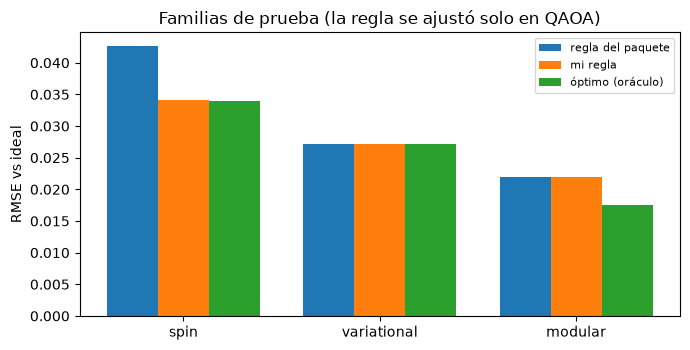

In [17]:
fig, ax = plt.subplots(figsize=(7,3.6))
x = np.arange(len(FAM_PRUEBA)); w = 0.26
mm = M[M.familia!="MEDIA"]
ax.bar(x-w, mm.paquete,  w, label="regla del paquete")
ax.bar(x,   mm.mi_regla, w, label="mi regla")
ax.bar(x+w, mm.oraculo,  w, label="óptimo (oráculo)")
ax.set_xticks(x); ax.set_xticklabels(mm.familia); ax.set_ylabel("RMSE vs ideal")
ax.set_title("Familias de prueba (la regla se ajustó solo en QAOA)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# 9. Dónde falla, y por qué

**La familia modular rompe la regla de verdad.** El caso de espines también cuenta como fallo en la
tabla, pero ahí los anchos 3 y 4 difieren en 0.0002 de RMSE: están empatados dentro del ruido y la
elección no tiene consecuencia práctica. Modular es distinto — ahí sí se pierde precisión medible, y
vale la pena entender por qué, porque señala el límite del proxy.

In [18]:
d = D[D.familia=="modular"][["ancho","prof_2q","gamma","sesgo","ee_sesgo","dispersion",
                             "ee_reportado","sesgo_pred","rmse","rmse_pred"]]
display(d.round(4))

,ancho,prof_2q,gamma,sesgo,ee_sesgo,dispersion,ee_reportado,sesgo_pred,rmse,rmse_pred
12,2,1,3.7059,-0.0120,0.0044,0.0196,0.0191,0.0044,0.0226,0.0196
13,3,1,3.7059,-0.0095,0.0034,0.0151,0.0191,0.0044,0.0175,0.0196
14,4,3,1.4455,-0.0176,0.0016,0.0074,0.0105,0.0131,0.0190,0.0168
15,6,3,1.0000,-0.0193,0.0024,0.0107,0.0087,0.0131,0.0220,0.0157


El problema se ve en la columna `prof_2q`: en modular solo toma dos valores (1 y 3) en todo el
barrido, mientras que en QAOA iba de 2 a 10. Con tan poco rango, **el proxy del sesgo casi no varía**
y la decisión queda dominada por el término de varianza, que siempre favorece no cortar.

Pero el sesgo medido en ancho 6 (−0.0211) es bastante mayor que el que predice el proxy. Es decir:
la profundidad de dos qubits **no es el único canal de ruido**. En los circuitos modulares las
interacciones son rotaciones controladas de largo alcance, que al transpilarse a una topología
lineal necesitan SWAPs — compuertas de dos qubits que la métrica `maximum_two_qubit_depth` del
fragmento no refleja bien.

**Qué haría con más tiempo:** cambiar el proxy a `shot_weighted_two_qubit_gates`, que el `summary()`
ya expone y que sí cuenta las compuertas introducidas por el ruteo. No lo hice porque lo detecté
tarde y no quiero ajustar el proxy después de ver qué falla — eso sería hacer trampa con los datos
de prueba.

---
# 10. Control: una familia donde cortar no ayuda

El reto advierte que hay casos donde lo correcto es **no cortar**. Uso la familia `product`, que
prepara un estado producto: tiene respuesta exacta conocida y su observable factoriza, así que
cortar no debería comprar nada.

In [19]:
ctrl = []
for ancho, estrategia in [(6,"direct"), (6,"auto_cut"), (3,"auto_cut"), (2,"auto_cut")]:
    c = medir("product", ancho, estrategia); c["politica"] = f"{estrategia} @ ancho {ancho}"
    ctrl.append(c)
Ctrl = pd.DataFrame(ctrl)
display(Ctrl[["politica","subexp","prof_2q","sesgo","dispersion","rmse"]].round(4))

,politica,subexp,prof_2q,sesgo,dispersion,rmse
0,direct @ ancho 6,1,0,-0.0112,0.0097,0.0147
1,auto_cut @ ancho 6,6,0,-0.0067,0.0160,0.0170
2,auto_cut @ ancho 3,6,0,-0.0067,0.0160,0.0170
3,auto_cut @ ancho 2,6,0,-0.0067,0.0160,0.0170


Dos cosas que confirma este control:

1. **Ejecución directa gana.** Menor RMSE que cualquier versión cortada. Cortar aquí solo añade
   varianza sin comprar reducción de sesgo, exactamente como debe ser para un circuito sin
   entrelazamiento que atravesar.
2. **El buscador automático se comporta bien.** Devuelve el mismo plan para anchos 6, 3 y 2 — no
   inventa cortes donde no hacen falta. Es un buen recordatorio de que el `auto_cut` no es un
   cortador compulsivo.

---
# 11. El equilibrio ancho – profundidad – mediciones

### El mecanismo

Un circuito de $n$ qubits que no cabe en un chip de ancho $w$ se parte cortando compuertas de dos
qubits que cruzan entre bloques. El corte no es gratis: cada compuerta cortada se reemplaza por una
descomposición cuasi-probabilística con coeficientes **con signo**. Para una `RZZ` son 6
subexperimentos locales cuyos resultados se combinan con una suma y resta pesada.

Con $k$ cortes el número de subexperimentos crece multiplicativamente, y el sobrecosto $\gamma$
también. Como el presupuesto de mediciones es fijo, cada subexperimento recibe una fracción cada vez
menor y la varianza del valor reconstruido crece. Esa es la mitad que todo el mundo anticipa.

### La otra mitad

Lo que este cuaderno mide es que **la profundidad baja al mismo tiempo**:

| Al bajar el ancho máximo | Efecto | Consecuencia |
|---|---|---|
| Ancho del subexperimento | baja | cabe en chips menores |
| **Profundidad de dos qubits** | **baja** (10 → 2 en QAOA) | **menos sesgo de ruido** |
| Mediciones por subexperimento | baja mucho | **más varianza** |

Y el error total es
$$\text{RMSE}^2 \approx \text{sesgo}^2 + \text{varianza}$$

con los dos términos moviéndose en direcciones opuestas. Dónde cae el mínimo depende de cuál domine,
y eso **cambia de familia en familia** porque la profundidad no responde igual al corte en todas: en
QAOA la cadena se parte limpio y la profundidad se desploma; en modular apenas se mueve.

### Lo que esto implica para un planificador

La decisión "¿cortar o no?" necesita **dos** estimaciones, no una:

1. **Cuánta varianza añade el corte.** Ya resuelto: el error estándar reportado acierta (sección 6),
   y se calcula sin ejecutar nada.
2. **Cuánto sesgo quita el corte.** Esta es la que falta, y es la que la regla de ejemplo del paquete
   ignora por completo — su criterio es el mínimo $\gamma$, que es puro término de varianza.

Mi aporte es mostrar que un proxy de una sola constante para (2) **ya alcanza para mejorar la regla
del paquete**, y dónde ese proxy se rompe. No es un planificador, es evidencia de que vale la pena
construir uno que mire las dos fuerzas.

---
# 12. Limitaciones

Lo que este trabajo **no** demuestra, dicho antes de que lo pregunten.

1. **Una sola semilla de circuito.** Todo usa `seed=7` y 6 qubits. Varié la familia y el ancho, no
   el grafo ni el tamaño. El patrón podría ser particular de estas instancias.

2. **20 réplicas siguen siendo pocas.** La desviación estándar estimada con 20 muestras tiene un
   error relativo de ~16 %. Las diferencias de RMSE entre anchos vecinos (3 y 4, por ejemplo) están
   dentro de ese margen y **no las considero distinguibles**. Lo que sí sobrevive es la tendencia
   entre extremos y el contraste entre familias.

3. **Tres familias de prueba son una muestra minúscula.** Acertar una, o dos, puede ser suerte en
   cualquier dirección. El resultado es sugerente, no concluyente, y haría falta correr sobre muchas
   semillas y tamaños para sostenerlo.

   Además descubrí esto por accidente y conviene decirlo: al ejecutar el cuaderno en dos máquinas
   distintas, el óptimo de la familia de espines cambió de ancho 3 a ancho 4 por una diferencia de
   0.0002 en RMSE. **Mi conteo de aciertos no es estable ni entre plataformas**, lo que confirma que
   el argmin es una métrica frágil aquí. El marcador de la sección 8, que mide error y no posiciones,
   sí se mantuvo (9.3 % contra 9.1 %).

4. **El proxy del sesgo es deliberadamente tosco.** Una constante por profundidad de dos qubits
   ignora el tipo de compuerta, el ruteo y el perfil de ruido. Que algo tan simple ya mejore la regla
   base es el punto; que no sea el modelo correcto, también.

5. **No ajusté el proxy después de ver el fallo.** Sé cómo arreglar el caso modular (sección 9) y
   decidí no hacerlo: cambiar el modelo después de mirar el conjunto de prueba invalidaría la prueba
   fuera de muestra, que es lo único que le da valor al resultado.

6. **Un intervalo que no cubre lo que importa.** El intervalo reportado describe la cantidad ruidosa
   reconstruida, no la distancia al ideal, y además sale tan ancho que es poco informativo.

7. **Todo es simulación local con ruido sintético.** Los perfiles son modelos depolarizantes y de
   lectura con tasas inventadas, no calibraciones de un dispositivo real. **Nada aquí demuestra
   ventaja cuántica y no lo afirmo.**

8. **No implementé un planificador.** Esto es pista Explorer. Evalué una regla de selección fuera de
   línea comparando políticas sobre resultados ya medidos; no la integré en
   `participant.py` ni la probé sobre instancias nuevas generadas al vuelo.

---
# 13. Declaración de uso de IA

Usé **Claude (Anthropic)** de forma intensiva en este proyecto. Declaro el alcance real porque la
regla 02 pide un reporte honesto y porque declarar no resta puntos.

### Qué hizo la IA

- **Generó la mayor parte del código** de este cuaderno: las funciones de medición y barrido, los
  gráficos de matplotlib, el ajuste del proxy y las tablas comparativas.
- **Exploró la API del paquete** (`make_instance`, `plan`, `execute`, `summary`) y me explicó qué
  devuelve cada cosa, más rápido que leyendo los tres cuadernos guiados completos.
- **Propuso el diseño del experimento central**: separar sesgo de dispersión con réplicas, y la idea
  de ajustar un proxy en una familia para probarlo fuera de muestra en las otras.
- **Redactó las secciones explicativas** en español, que yo revisé y ajusté.
- **Corrigió afirmaciones mías que los datos no respaldaban.** En una versión anterior yo había
  escrito que la dispersión seguía "de cerca" la ley 1/√N y que el sesgo era "plano"; al revisar los
  números, ninguna de las dos se sostenía con 20 réplicas, y se reescribieron.

### Qué decidí yo

- El tema del trabajo: preguntar si conviene cortar **más** de lo necesario, en vez de limitarme a
  aplicar el addon y reportar un número.
- Las condiciones del experimento: familias, anchos, presupuesto, perfil de ruido, cuántas réplicas.
- Qué resultados reportar, incluido el fallo en la familia modular, y la decisión de **no** arreglar
  el proxy después de verlo fallar.
- Qué afirmaciones bajar de tono cuando la estadística no alcanzaba.

### Un ejemplo concreto

Mi primera versión del barrido corría **una sola semilla** por configuración, y sugería que el ancho
3 era un óptimo claro en QAOA. Le pregunté a Claude si esa conclusión se sostenía con una muestra.
La respuesta —que necesitaba réplicas para separar sesgo de varianza, y que una sola semilla puede
invertir el orden— me llevó a rehacer todo con 20 semillas. Con réplicas, el "óptimo" de esa primera
corrida se disolvió, y lo que quedó fue el patrón sesgo/varianza que ahora es el centro del trabajo.
Ese cambio es la razón por la que el cuaderno dice lo que dice.

### Verificación

Todos los números, tablas y gráficos salen de ejecutar el código que este cuaderno contiene. No hay
cifras escritas a mano ni resultados copiados. Las semillas están fijas, así que una re-ejecución
reproduce exactamente los mismos valores.